New pdf area is:  0.9999999999999999
Sum voxels before  1.0000000000000002
Sum voxels after  3375.0


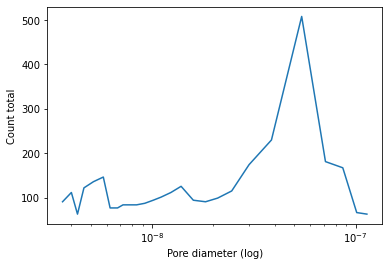

Area under throat distri  1.0
numThroats  9450
(27,)


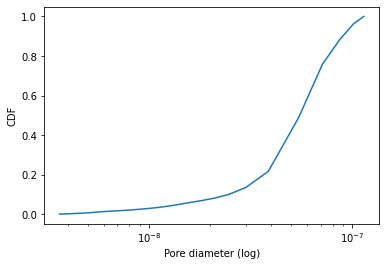

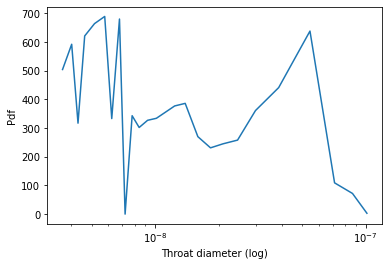

[array([[3.63599196e-09, 4.22410662e+06],
       [4.01794927e-09, 5.19890045e+06],
       [4.30564104e-09, 2.92438150e+06],
       [4.63169242e-09, 5.68629737e+06],
       [5.15772624e-09, 6.33615992e+06],
       [5.76561161e-09, 6.82355684e+06],
       [6.22609575e-09, 3.57424406e+06],
       [6.77521760e-09, 3.57424406e+06],
       [7.20476098e-09, 3.89917534e+06],
       [7.78018616e-09, 3.89917534e+06],
       [8.40156904e-09, 3.89917534e+06],
       [9.21308110e-09, 4.06164098e+06],
       [1.01418669e-08, 4.38657226e+06],
       [1.10788296e-08, 4.71150353e+06],
       [1.23845713e-08, 5.19890045e+06],
       [1.38974972e-08, 5.84876301e+06],
       [1.59589141e-08, 4.38657226e+06],
       [1.83261011e-08, 4.22410662e+06],
       [2.10032379e-08, 4.60768013e+06],
       [2.46346367e-08, 5.36136609e+06],
       [2.99668236e-08, 8.12328195e+06],
       [3.86156252e-08, 1.07227322e+07],
       [5.43577412e-08, 2.37199833e+07],
       [7.11308244e-08, 8.44821323e+06],
       [8.65271

In [1]:
from cubic import *
from adsorb import *

numNodes = 15
dx = 150e-9
inFile = 'dgp.xlsx'
sheet = 'PoreSizeDistribution'

ell = makeCubicNet(numNodes,dx,inFile,sheet)
print(ell)

## Modification
#ell[2]['throat.diameter'] *= 0.9
#ell[2]['throat.length'] = 150e-9

In [2]:
tid = 6859
p = ell[2]['throat.conns'][tid]
print(ell[2]['pore.diameter'][p[0]])
print(ell[2]['pore.diameter'][p[1]])
print(ell[2]['throat.diameter'][tid])
#plt.hist(g['throat.length'])
1.8326101089319403e-08*0.9

8.65271484519882e-08
4.017949272550381e-09
4.017949272550381e-09


1.6493490980387464e-08

In [25]:
print(min(ell[1]['pore.coords'][:,0]))
(150e-9)*15 - (75e-9)

7.5e-08


2.175e-06

In [3]:
[pres,finalVolN2,finalVolN2_desorb,p1] = adsorb(ell[1],ell[2],dx)
isotherm = pd.read_excel('dgp2.xlsx',sheet_name = 'Sheet1')

Thickness Harkins-Jura in nm:  [[0.        ]
 [0.17365556]
 [0.18817009]
 [0.19859074]
 [0.20714195]
 [0.21459816]
 [0.22132991]
 [0.22754628]
 [0.23337809]
 [0.23891329]
 [0.24421425]
 [0.24932702]
 [0.25428678]
 [0.25912116]
 [0.26385231]
 [0.2684984 ]
 [0.27307459]
 [0.27759372]
 [0.28206681]
 [0.28650347]
 [0.29091217]
 [0.29530046]
 [0.29967514]
 [0.30404242]
 [0.30840798]
 [0.31277711]
 [0.31715478]
 [0.32154566]
 [0.3259542 ]
 [0.33038469]
 [0.33484125]
 [0.33932793]
 [0.34384865]
 [0.34840734]
 [0.35300784]
 [0.35765403]
 [0.36234979]
 [0.36709901]
 [0.37190567]
 [0.3767738 ]
 [0.38170752]
 [0.38671105]
 [0.39178875]
 [0.39694511]
 [0.4021848 ]
 [0.40751264]
 [0.41293369]
 [0.41845322]
 [0.42407675]
 [0.42981007]
 [0.43565929]
 [0.44163084]
 [0.44773151]
 [0.45396852]
 [0.46034951]
 [0.46688261]
 [0.47357647]
 [0.48044035]
 [0.48748415]
 [0.49471847]
 [0.50215469]
 [0.50980508]
 [0.51768286]
 [0.52580232]
 [0.53417892]
 [0.54282947]
 [0.55177225]
 [0.56102717]
 [0.57061603]
 [0

KeyboardInterrupt: 

In [ ]:
plt.plot(pres,finalVolN2,label='Shell Simulation Adsorption')
plt.plot(pres[0:99],finalVolN2_desorb[0:99],label='Shell Simulation Desorption')
plt.plot(isotherm['p_ads'],isotherm['v_ads']*1e-27,label='Hannach Adsorption')
plt.plot(isotherm['p_deso'],isotherm['v_deso']*1e-27,label='Hannach Desorption')
plt.xlabel('p/p0')
plt.ylabel('Vol of N2 in m^3')
plt.legend()

In [ ]:
a1 = np.zeros((25,3))
#pres2 = pres[0:49]
a1[:,0] = pres
a1[:,1] = finalVolN2
a1[:,2] = finalVolN2_desorb
print(a1)
np.savetxt('ad_throatDis.txt',a1)
#a1[0:49,2] = finalVolN2_desorb

In [ ]:
pn2 = op.network.Cubic(shape=[10, 10, 10], spacing=1, connectivity=6)
geo2 = op.geometry.GenericGeometry(network=pn2, pores=pn2.Ps, throats=pn2.Ts)

#print(pn2)
print(geo2)

#geo2.add_model(propname='pore.diameter',model=op.models.misc.random,element='pore',num_range=[0.1, 0.8])
geo2['pore.diameter'] = 0.5

numPores = len(pn2.Ps)

# Single pore diameter
geo2['pore.diameter'][0:1000] = 0.5
geo2['pore.diameter'][115] = 0.25
geo2['pore.diameter'][215] = 0.25


#for i in range(numPores*0.5):
#geo2['pore.diameter'][0:500] = 0.61
#geo2['pore.diameter'][500:1000] = 0.25

geo2.show_hist('pore.diameter')

plt.show()

f = op.models.misc.from_neighbor_pores
geo2.add_model(propname='throat.diameter', model=f, prop='pore.diameter', mode='min')
    
f = op.models.geometry.throat_length.classic
geo2.add_model(propname='throat.length',model=f,pore_diameter='pore.diameter' )

#[isPoreVisited,isThroatVisited,openPores,blockedPores,blockedThroats] = adsorb(pn2,geo2,1)
[isPoreVisited,isThroatVisited,p1] = adsorb(pn2,geo2,1)

In [ ]:
# Num throats and pores visited
print('Num Pores visited: ',np.sum(isPoreVisited))
print('Num Throats visited: ',np.sum(isThroatVisited))

pv = np.where(isPoreVisited==1)
tv = np.where(isThroatVisited==1)

x = pn2.find_neighbor_throats(pores=[115])
x2 = pn2.find_neighbor_throats(pores=[215])
print('Neighbour throats 115: ',x)
print('Neighbour throats 215: ',x2)
y = pn2.find_neighbor_pores(pores=[115])
y2 = pn2.find_neighbor_pores(pores=[215])
print('Neighbour pores 115: ',y)
print('Neighbour pores 215: ',y2)
#print(isPoreVisited[115])
print(isPoreVisited[y2])
print('Blocked pores: ',p1.blockedPores)
print('Blocked throats: ',p1.blockedThroats)
print(pn2.find_connecting_throat(115,215))

In [ ]:
pdf2 = ell[0]
net = ell[1]
geo = ell[2]
print(geo)
#print(geo['pore.diameter'])
dia = geo['pore.diameter']
tdia = geo['throat.diameter']
tlen = geo['throat.length']
    
plt.xscale('log')
y,x = np.histogram(dia,bins=pdf2[:,0])
#y,x = np.histogram(dia,bins=25)
plt.plot(x[0:-1],y)
plt.xlabel('Pore diameter (log)')
plt.ylabel('Count total')
plt.show()
print(x)

In [ ]:
-4.16/(np.log10(0.4))

In [ ]:
x = geo['throat.conns'][15326]
print(x)
x[0]
r1 = 0.5*geo['pore.diameter'][x[0]]
print(r1)
r2 = 0.5*geo['pore.diameter'][x[1]]
print(r2)
#tlen = geo['throat.length'][15326]
#print(tlen)
#print(150e-9 - (r1 + r2))
tdia = geo['throat.diameter'][15326]
print(tdia*0.5)

In [ ]:
#poreX = np.where(net['pore.coords'][:][0] == 7.5e-8)
poreX = []

for i in range(len(net['pore.coords'])):
        if (net['pore.coords'][i][0] == dx*0.5):
            poreX.append([i])

#print(net['pore.coords'][0][0])
#print(poreX)
Ts = net.find_neighbor_throats(pores=[500941])
print(Ts)
z = geo['throat.conns'][495932]
print(z)
p1 = 500941
t = z[1] if z[0] == p1 else z[0]
print(t)

In [ ]:
x = geo2['throat.conns'][2033]
print(x)
x[0]
r1 = 0.5*geo2['pore.diameter'][x[0]]
print(r1)
r2 = 0.5*geo2['pore.diameter'][x[1]]
print(r2)
#tlen = geo['throat.length'][15326]
#print(tlen)
#print(150e-9 - (r1 + r2))
tdia = geo2['throat.diameter'][2033]
print(tdia*0.5)
tlen = geo2['throat.length'][2033]
print('Throat length', tlen)
print('gap ',1 - (r1 + r2))

In [ ]:
pdfRaw = pd.read_excel(inFile,sheet_name = 'PoreSizeDistribution')
pdfRaw['pDia'] *= 1e-9
pdfRaw['v'] *= 1e-3
pdfArr = pdfRaw.to_numpy()
pdfArr[:,1] /= (np.pi/6)*(pdfArr[:,0]**3)
plt.xscale('log')
fig1 = plt.plot(pdfArr[:,0],pdfArr[:,1])
plt.xlabel('Pore diameter (log)')
plt.ylabel('Count total')
plt.show()

In [ ]:
pn = op.network.Cubic(shape=[15,15,15], spacing=dx, connectivity=6)
geo = op.geometry.GenericGeometry(network=pn, pores=pn.Ps, throats=pn.Ts)
print(pn['pore.coords'][1])
print('Pore 0',pn.find_neighbor_throats(pores=[0]))
print('Pore 1',pn.find_neighbor_throats(pores=[1]))
print('Pore 2',pn.find_neighbor_throats(pores=[2]))
print('Numthroats ',len(pn.Ts))

op.topotools.extend(network = pn,throat_conns=[[1,2]])

#op.topotools.trim(network = pn,pores=[1])
#print('Pore 0',pn.find_neighbor_throats(pores=[0]))
print('Pore 1',pn.find_neighbor_throats(pores=[1]))
print('Pore 2',pn.find_neighbor_throats(pores=[2]))
print('Numthroats ',len(pn.Ts))

In [ ]:
z  = np.arange(10)
print(z)
(np.random.shuffle(z))
print(z[0])